# ML Project: Предсказание цены смартфона

Предсказание цены смартфона на основе технических характеристик.

**Датасет**: smartphone_cleaned_v5.csv (980 смартфонов)

**Pipeline**: EDA → Очистка → Feature Engineering → Модели → Тюнинг → Интерпретация

## 1. Импорты и настройки

In [23]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

try:
    from xgboost import XGBRegressor
    xgb_available = True
except ImportError:
    xgb_available = False

try:
    from lightgbm import LGBMRegressor
    lgb_available = True
except ImportError:
    lgb_available = False

from IPython.display import display

%matplotlib inline
sns.set_style('whitegrid')
print('Все импорты загружены.')

Все импорты загружены.


## 2. Вспомогательные функции

**`detect_price_column(df)`** — находит столбец с ценой по имени, содержащему "price".

**`evaluate_regression(name, y_true, y_pred)`** — считает MAE, MSE, RMSE, R² и выводит их. Возвращает словарь для таблицы сравнения моделей.

**`cap_outliers(series)`** — обрезает выбросы по IQR (Q1 − 1.5·IQR, Q3 + 1.5·IQR). Применяется к каждому числовому признаку и к target, чтобы экстремальные значения не искажали обучение.

**`reduce_high_cardinality_categories(df, categorical_features, top_n)`** — группирует редкие категории (встречаются реже top_n раз) в "Other". Уменьшает число фиктивных переменных после one-hot encoding.

**`get_feature_names(transformer)`** — извлекает имена признаков из ColumnTransformer (для визуализации feature importance).

**`downsample_preserve_distribution(df, group_col, target_n, random_state)`** — уменьшает размер датасета до target_n строк, сохраняя пропорции групп. В проекте не применяется (данные и так меньше 100k), но оставлена для масштабирования.

In [24]:
def detect_price_column(df):
    candidates = [c for c in df.columns if 'price' in c.lower()]
    if len(candidates) > 0:
        return candidates[0]
    raise ValueError('Столбец с ценой не найден.')

def evaluate_regression(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f'[{name}] MAE: {mae:.3f}, MSE: {mse:.3f}, RMSE: {rmse:.3f}, R2: {r2:.3f}')
    return {'model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

def cap_outliers(series):
    if series.dtype.kind not in 'bifc':
        return series
    q1, q3 = np.percentile(series.dropna(), [25, 75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series.clip(lower, upper)

def reduce_high_cardinality_categories(df, categorical_features, top_n=30):
    for col in categorical_features:
        if df[col].nunique(dropna=False) > top_n:
            top_values = df[col].value_counts(dropna=False).nlargest(top_n).index
            df[col] = df[col].where(df[col].isin(top_values), other='Other')
    return df

def get_feature_names(transformer):
    try:
        return transformer.get_feature_names_out()
    except Exception:
        names = []
        for name, step, cols in transformer.transformers_:
            if name == 'remainder':
                continue
            if hasattr(step, 'get_feature_names_out'):
                names.extend(step.get_feature_names_out(cols))
            else:
                names.extend(cols)
        return names

def downsample_preserve_distribution(df, group_col='brand', target_n=100000, random_state=42):
    if len(df) <= target_n:
        return df
    if group_col not in df.columns:
        raise ValueError(f"Столбец '{group_col}' не найден.")
    counts = df[group_col].value_counts()
    if (counts < 2).any():
        proportions = counts / counts.sum()
        target_counts = np.floor(proportions * target_n).astype(int)
        remainder = target_n - target_counts.sum()
        for idx in counts.index[:remainder]:
            target_counts[idx] += 1
        sampled = (
            df.groupby(group_col, group_keys=False)
            .apply(lambda x: x.sample(n=min(len(x), int(target_counts.loc[x.name])), random_state=random_state))
            .reset_index(drop=True)
        )
        if len(sampled) > target_n:
            sampled = sampled.sample(n=target_n, random_state=random_state).reset_index(drop=True)
        return sampled
    sampled, _ = train_test_split(df, train_size=target_n, stratify=df[group_col], random_state=random_state)
    return sampled.reset_index(drop=True)

print('Вспомогательные функции определены.')

Вспомогательные функции определены.


## 3. Загрузка данных

In [25]:
df = pd.read_csv('smartphone_cleaned_v5.csv', low_memory=False)
print(f'Размер: {df.shape}')
display(df.head())

Размер: (980, 25)


,brand_name,model,price,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,...,screen_size,refresh_rate,resolution,num_rear_cameras,num_front_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto
0,oneplus,OnePlus 11 5G,54999,89.0,True,True,False,snapdragon,8.0,3.2,...,6.70,120,1440 x 3216,3,1.0,android,50.0,16.0,0,NaN
1,oneplus,OnePlus Nord CE 2 Lite 5G,19989,81.0,True,False,False,snapdragon,8.0,2.2,...,6.59,120,1080 x 2412,3,1.0,android,64.0,16.0,1,1024.0
2,samsung,Samsung Galaxy A14 5G,16499,75.0,True,False,False,exynos,8.0,2.4,...,6.60,90,1080 x 2408,3,1.0,android,50.0,13.0,1,1024.0
3,motorola,Motorola Moto G62 5G,14999,81.0,True,False,False,snapdragon,8.0,2.2,...,6.55,120,1080 x 2400,3,1.0,android,50.0,16.0,1,1024.0
4,realme,Realme 10 Pro Plus,24999,82.0,True,False,False,dimensity,8.0,2.6,...,6.70,120,1080 x 2412,3,1.0,android,108.0,16.0,0,NaN


## 4. EDA — Первичный обзор

In [26]:
display(df.describe(include='all').transpose())
print(f'\nКолонки: {df.columns.tolist()}\n')

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand_name,980,46,xiaomi,134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,980,980,OnePlus 11 5G,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,980.0,NaN,NaN,NaN,32520.504082,39531.812669,3499.0,12999.0,19994.5,35491.5,650000.0
rating,879.0,NaN,NaN,NaN,78.258248,7.402854,60.0,74.0,80.0,84.0,89.0
has_5g,980,2,True,549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_nfc,980,2,False,587,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_ir_blaster,980,2,False,821,NaN,NaN,NaN,NaN,NaN,NaN,NaN
processor_brand,960,13,snapdragon,413,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_cores,974.0,NaN,NaN,NaN,7.772074,0.836845,4.0,8.0,8.0,8.0,8.0
processor_speed,938.0,NaN,NaN,NaN,2.427217,0.46409,1.2,2.05,2.3,2.84,3.22



Колонки: ['brand_name', 'model', 'price', 'rating', 'has_5g', 'has_nfc', 'has_ir_blaster', 'processor_brand', 'num_cores', 'processor_speed', 'battery_capacity', 'fast_charging_available', 'fast_charging', 'ram_capacity', 'internal_memory', 'screen_size', 'refresh_rate', 'resolution', 'num_rear_cameras', 'num_front_cameras', 'os', 'primary_camera_rear', 'primary_camera_front', 'extended_memory_available', 'extended_upto']



### Пропуски и дубликаты

In [27]:
missing_counts = df.isna().sum().sort_values(ascending=False)
display(missing_counts[missing_counts > 0].to_frame('число пропусков'))
print(f'Дубликатов строк: {df.duplicated().sum()}')

,число пропусков
extended_upto,480
fast_charging,211
rating,101
processor_speed,42
processor_brand,20
os,14
battery_capacity,11
num_cores,6
primary_camera_front,5
num_front_cameras,4


Дубликатов строк: 0


## 5. Очистка данных

In [28]:
df = df.drop_duplicates().reset_index(drop=True)
print(f'После удаления дубликатов: {df.shape}')

После удаления дубликатов: (980, 25)


### Удаление столбца-ID (`model`) и парсинг `resolution`

In [29]:
if 'model' in df.columns:
    df.drop(columns=['model'], inplace=True)
    print('Удалён столбец model — 980 уникальных значений (работает как ID).')

if 'resolution' in df.columns:
    res_split = df['resolution'].astype(str).str.extract(r'(\d+)\s*[x×]\s*(\d+)', expand=True)
    if res_split.notna().any().any():
        df['screen_width'] = pd.to_numeric(res_split[0], errors='coerce')
        df['screen_height'] = pd.to_numeric(res_split[1], errors='coerce')
        print('resolution разобран на screen_width и screen_height.')
    df.drop(columns=['resolution'], inplace=True)

Удалён столбец model — 980 уникальных значений (работает как ID).
resolution разобран на screen_width и screen_height.


### Целевая переменная и типы признаков

In [30]:
target_col = detect_price_column(df)
print(f'Целевая переменная: {target_col}')

numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()
if target_col in numeric_features:
    numeric_features.remove(target_col)
elif target_col in categorical_features:
    categorical_features.remove(target_col)

print(f'Числовые признаки ({len(numeric_features)}): {numeric_features}')
print(f'Категориальные признаки ({len(categorical_features)}): {categorical_features}')

Целевая переменная: price
Числовые признаки (18): ['rating', 'num_cores', 'processor_speed', 'battery_capacity', 'fast_charging_available', 'fast_charging', 'ram_capacity', 'internal_memory', 'screen_size', 'refresh_rate', 'num_rear_cameras', 'num_front_cameras', 'primary_camera_rear', 'primary_camera_front', 'extended_memory_available', 'extended_upto', 'screen_width', 'screen_height']
Категориальные признаки (3): ['brand_name', 'processor_brand', 'os']


## 6. EDA — Визуализации ДО удаления выбросов

Строим графики на сырых данных, чтобы увидеть проблему.

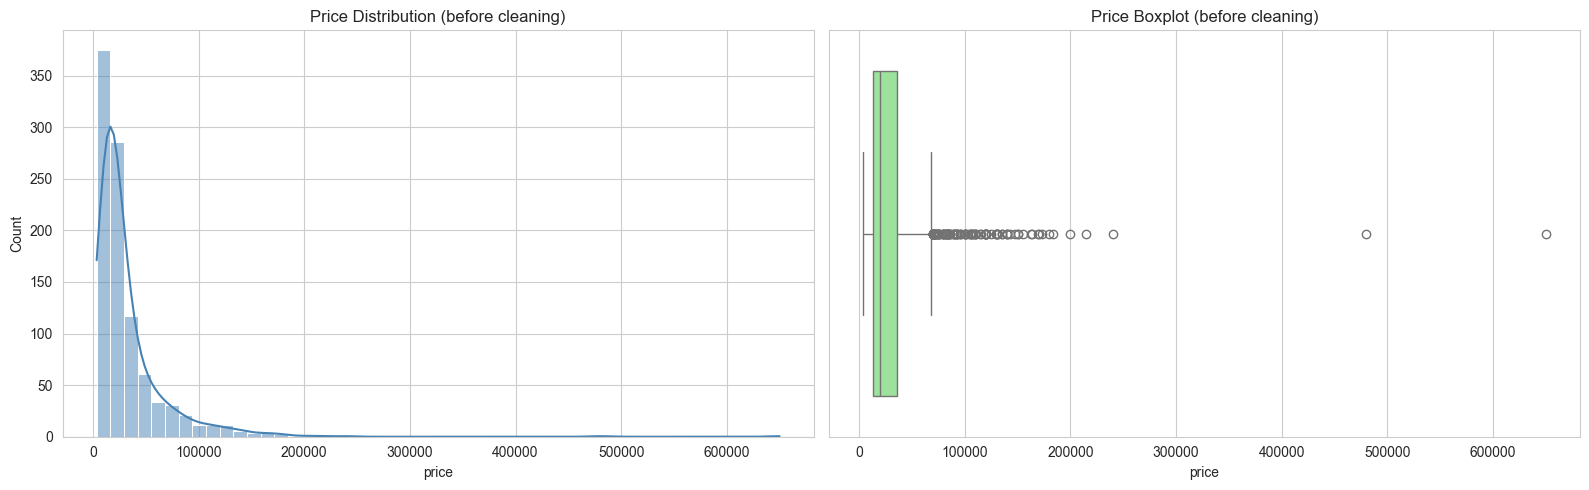

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(df[target_col].dropna(), kde=True, bins=50, color='steelblue', ax=axes[0])
axes[0].set_title('Price Distribution (before cleaning)')
axes[0].set_xlabel(target_col)

sns.boxplot(x=df[target_col].dropna(), color='lightgreen', ax=axes[1])
axes[1].set_title('Price Boxplot (before cleaning)')

plt.tight_layout()
plt.show()

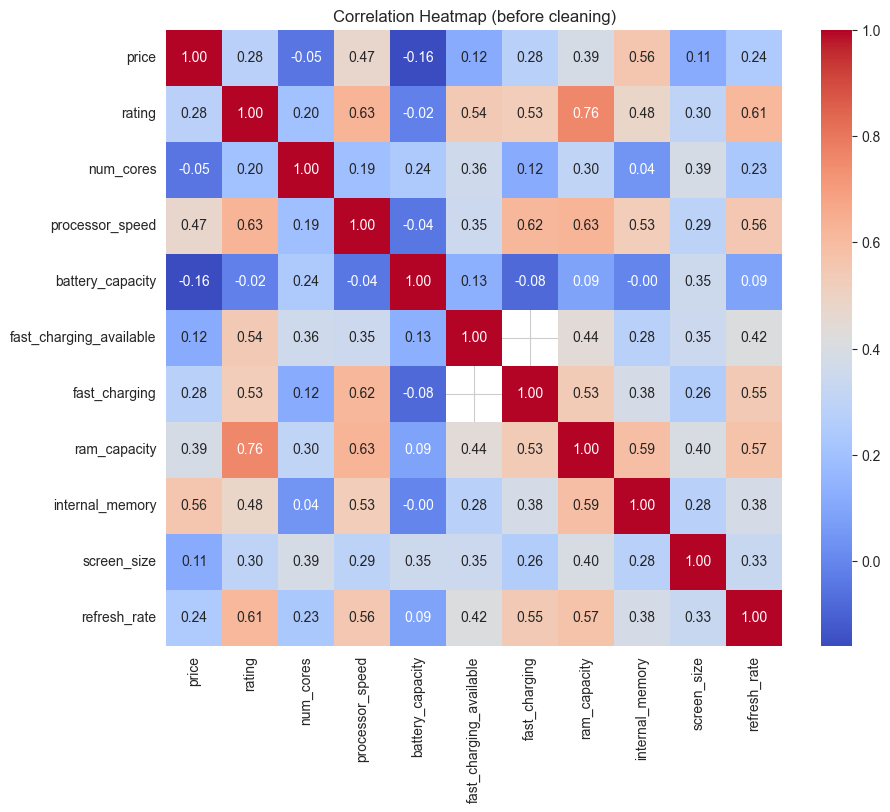

In [32]:
if len(numeric_features) >= 2:
    numeric_for_corr = [target_col] + numeric_features[:10]
    corr = df[numeric_for_corr].corr()
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, ax=ax)
    ax.set_title('Correlation Heatmap (before cleaning)')
    plt.show()

## 7. Удаление выброса в target (price)

На boxplot видно одно наблюдение с ценой **650,000** при медиане ~20,000 и Q3 ~35,000.
Значение 650,000 более чем в 9 раз превышает Q3 — это экстремальный выброс.

**Почему удаляем только этот телефон:**
- Большинство цен лежат в диапазоне 3,500–35,000₽
- Одно значение 650,000 не отражает общий рынок (это может быть редкая премиум-модель или ошибка данных)
- Если оставить его, модели будут «пытаться» его предсказать, искажая все остальные предсказания
- Удаление одного наблюдения не влияет на репрезентативность выборки (убираем 1 из 980)

**Решение:** удалим строку с price > 300,000.

In [33]:
# удаляем только экстремальный выброс — телефон с ценой 650,000
n_before = len(df)
df = df[df[target_col] <= 300000].reset_index(drop=True)
print(f'Удалено строк с price > 300000: {n_before - len(df)}')
print(f'Максимальная цена после фильтрации: {df[target_col].max():.0f}')

Удалено строк с price > 300000: 2
Максимальная цена после фильтрации: 239999


## 8. EDA — Визуализации ПОСЛЕ удаления выбросов

Теперь распределение цен стало информативным.

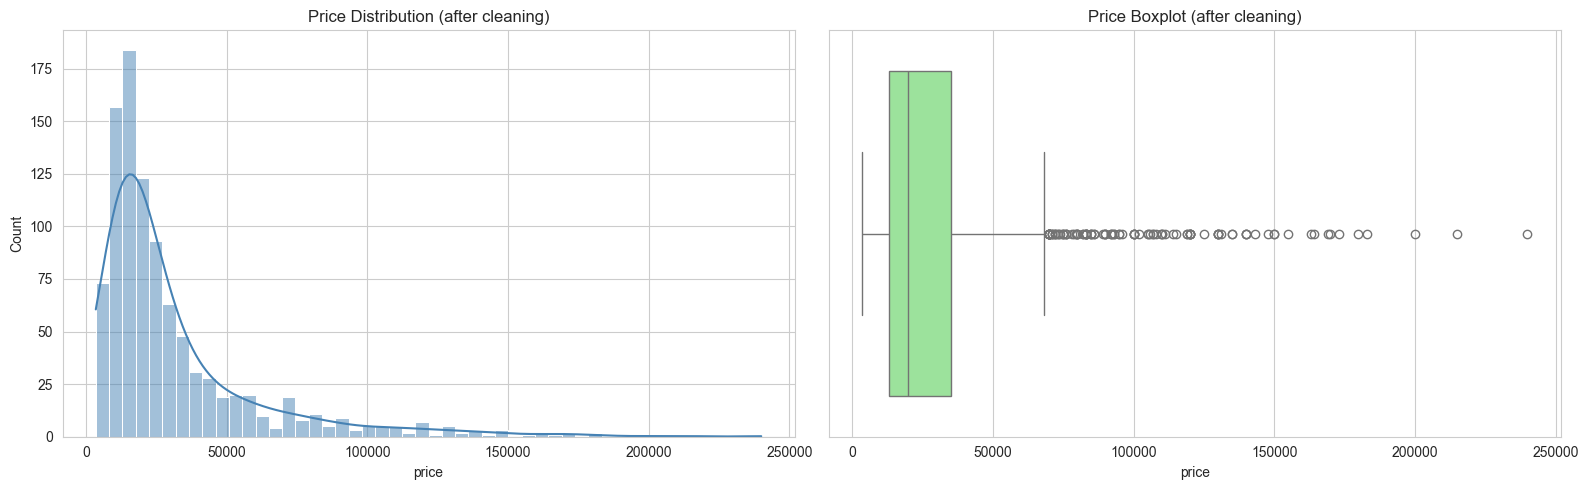

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(df[target_col].dropna(), kde=True, bins=50, color='steelblue', ax=axes[0])
axes[0].set_title('Price Distribution (after cleaning)')
axes[0].set_xlabel(target_col)

sns.boxplot(x=df[target_col].dropna(), color='lightgreen', ax=axes[1])
axes[1].set_title('Price Boxplot (after cleaning)')

plt.tight_layout()
plt.show()

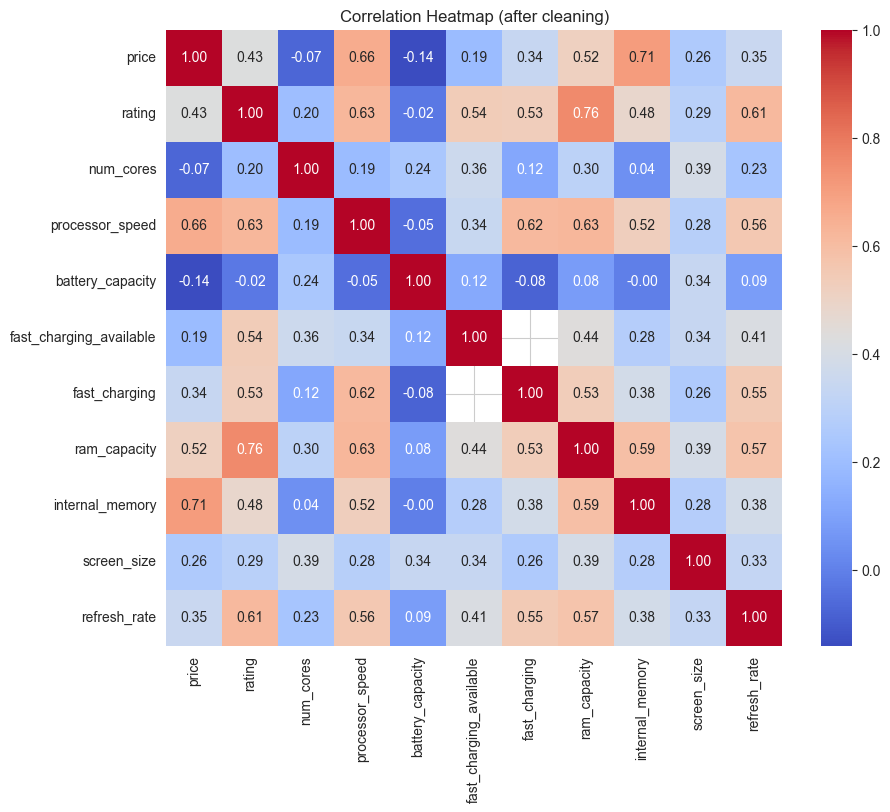

In [35]:
if len(numeric_features) >= 2:
    numeric_for_corr = [target_col] + numeric_features[:10]
    corr = df[numeric_for_corr].corr()
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, ax=ax)
    ax.set_title('Correlation Heatmap (after cleaning)')
    plt.show()

## 9. Feature Engineering

Обработка выбросов в признаках, очистка категориальных значений, создание `price_category`.

In [36]:
df[numeric_features] = df[numeric_features].apply(cap_outliers)

for col in categorical_features:
    df[col] = df[col].replace(['?', 'n/a', 'na', 'None', 'none', 'NULL', 'null'], np.nan)

df = reduce_high_cardinality_categories(df, categorical_features, top_n=25)

df['price_category'] = pd.qcut(df[target_col].rank(method='first'), q=4, labels=['low', 'medium', 'high', 'premium'])
print('Распределение price_category:')
display(df['price_category'].value_counts().to_frame())

Распределение price_category:


,count
price_category,
low,245
premium,245
medium,244
high,244


## 10. Разделение на train / test

In [37]:
X = df.drop(columns=[target_col, 'price_category'])
y = df[target_col]

numeric_features = [col for col in numeric_features if col in X.columns]
categorical_features = [col for col in categorical_features if col in X.columns]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Train: {len(X_train)} примеров, Test: {len(X_test)} примеров')

Train: 782 примеров, Test: 196 примеров


## 11. Pipeline предобработки

In [38]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

feature_selector = SelectKBest(mutual_info_regression, k=50)
print('Preprocessor и feature selector готовы.')

Preprocessor и feature selector готовы.


## 12. Baseline модель

In [39]:
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('select', feature_selector),
    ('model', DummyRegressor(strategy='median'))
])
baseline_pipeline.fit(X_train, y_train)
baseline_pred = baseline_pipeline.predict(X_test)
results = [evaluate_regression('Baseline', y_test, baseline_pred)]

[Baseline] MAE: 19143.592, MSE: 1087638942.653, RMSE: 32979.371, R2: -0.146


## 13. Обучение 7 моделей

In [40]:
models = {
    'LinearRegression': LinearRegression(),
    'DecisionTree': DecisionTreeRegressor(random_state=42),
    'KNN': KNeighborsRegressor(),
    'RandomForest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(random_state=42)
}
if xgb_available:
    models['XGBoost'] = XGBRegressor(random_state=42, verbosity=0, n_jobs=-1)
if lgb_available:
    models['LightGBM'] = LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1)

model_pipelines = {}
for name, estimator in models.items():
    print(f'Обучается {name}...')
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('select', feature_selector),
        ('model', estimator)
    ])
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)
    results.append(evaluate_regression(name, y_test, preds))
    model_pipelines[name] = pipeline

Обучается LinearRegression...
[LinearRegression] MAE: 11879.375, MSE: 280311477.016, RMSE: 16742.505, R2: 0.705
Обучается DecisionTree...
[DecisionTree] MAE: 8080.888, MSE: 435792097.038, RMSE: 20875.634, R2: 0.541
Обучается KNN...
[KNN] MAE: 6849.158, MSE: 172465579.550, RMSE: 13132.615, R2: 0.818
Обучается RandomForest...
[RandomForest] MAE: 6956.837, MSE: 229493312.282, RMSE: 15149.037, R2: 0.758
Обучается GradientBoosting...
[GradientBoosting] MAE: 7688.638, MSE: 266792310.699, RMSE: 16333.778, R2: 0.719
Обучается XGBoost...
[XGBoost] MAE: 7357.485, MSE: 264005760.000, RMSE: 16248.254, R2: 0.722
Обучается LightGBM...
[LightGBM] MAE: 7633.088, MSE: 187483510.571, RMSE: 13692.462, R2: 0.802


### Сравнение моделей

In [41]:
results_df = pd.DataFrame(results).sort_values('RMSE')
try:
    display(results_df.style.highlight_min(color='lightgreen', subset=['RMSE']))
except AttributeError:
    display(results_df)

,model,MAE,MSE,RMSE,R2
3,KNN,6849.158163,172465579.549592,13132.615107,0.818277
7,LightGBM,7633.087885,187483510.571002,13692.461816,0.802453
4,RandomForest,6956.836994,229493312.282060,15149.036678,0.758188
6,XGBoost,7357.485352,264005760.000000,16248.254060,0.721823
5,GradientBoosting,7688.637598,266792310.698945,16333.778213,0.718887
1,LinearRegression,11879.374801,280311477.015667,16742.505100,0.704642
2,DecisionTree,8080.887755,435792097.038265,20875.634051,0.540816
0,Baseline,19143.591837,1087638942.653061,32979.371471,-0.146021


## 14. Подбор гиперпараметров (RandomForest)

In [42]:
search_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('select', feature_selector),
    ('model', RandomForestRegressor(random_state=42, n_jobs=-1))
])

param_dist = {
    'model__n_estimators': [50, 100, 150],
    'model__max_depth': [None, 8, 16],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
search.fit(X_train, y_train)

best_rf = search.best_estimator_
print(f'\nЛучшие параметры: {search.best_params_}')
rf_pred = best_rf.predict(X_test)
rf_result = evaluate_regression('RandomForest_Tuned', y_test, rf_pred)

results_df = pd.concat([results_df, pd.DataFrame([rf_result])], ignore_index=True).sort_values('RMSE')
try:
    display(results_df.style.highlight_min(color='lightgreen', subset=['RMSE']))
except AttributeError:
    display(results_df)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Лучшие параметры: {'model__n_estimators': 50, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': None}
[RandomForest_Tuned] MAE: 6896.513, MSE: 223647817.134, RMSE: 14954.859, R2: 0.764


,model,MAE,MSE,RMSE,R2
0,KNN,6849.158163,172465579.549592,13132.615107,0.818277
1,LightGBM,7633.087885,187483510.571002,13692.461816,0.802453
8,RandomForest_Tuned,6896.513480,223647817.134343,14954.859315,0.764347
2,RandomForest,6956.836994,229493312.282060,15149.036678,0.758188
3,XGBoost,7357.485352,264005760.000000,16248.254060,0.721823
4,GradientBoosting,7688.637598,266792310.698945,16333.778213,0.718887
5,LinearRegression,11879.374801,280311477.015667,16742.505100,0.704642
6,DecisionTree,8080.887755,435792097.038265,20875.634051,0.540816
7,Baseline,19143.591837,1087638942.653061,32979.371471,-0.146021


## 15. Важность признаков

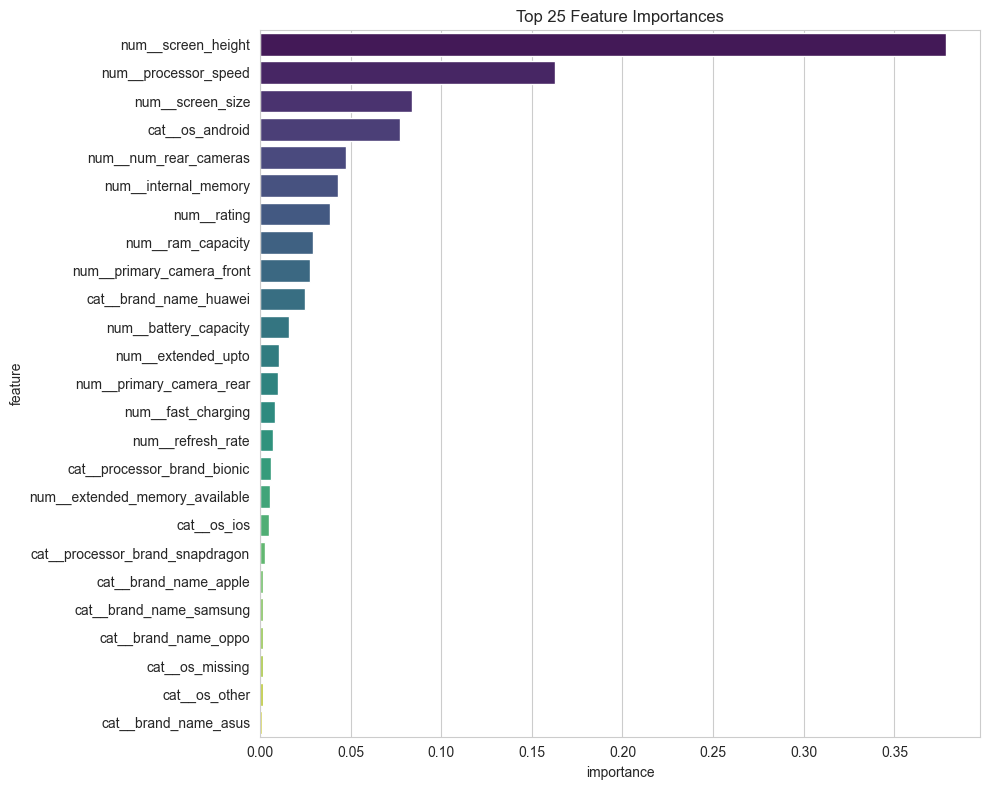

In [43]:
if hasattr(best_rf.named_steps['model'], 'feature_importances_'):
    try:
        all_feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()
    except Exception:
        all_feature_names = get_feature_names(best_rf.named_steps['preprocessor'])

    support = best_rf.named_steps['select'].get_support()
    feature_names = all_feature_names[support]
    importances = best_rf.named_steps['model'].feature_importances_

    importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
    importance_df = importance_df.sort_values(by='importance', ascending=False).head(25)

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.barplot(x='importance', y='feature', data=importance_df, palette='viridis', ax=ax)
    ax.set_title('Top 25 Feature Importances')
    plt.tight_layout()
    plt.show()

## 16. Фактические vs Предсказанные значения

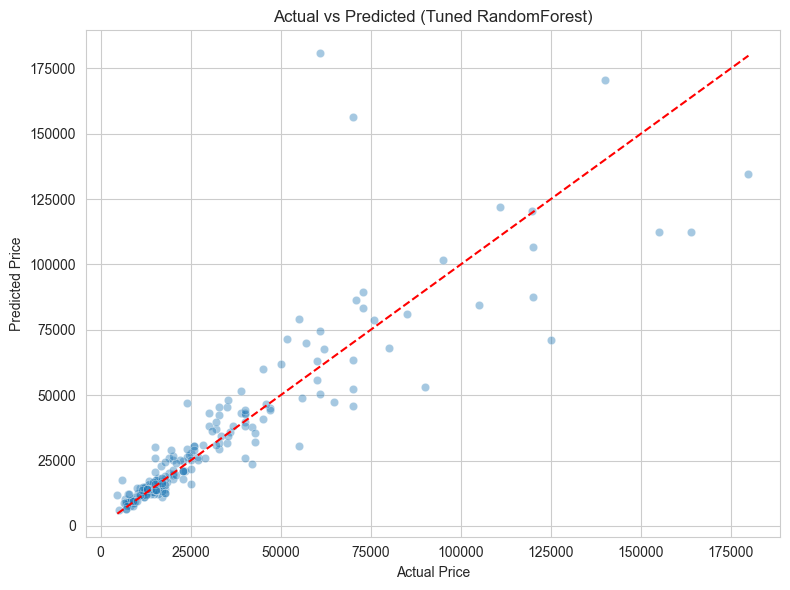

In [44]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=y_test, y=rf_pred, alpha=0.4, ax=ax)
ax.set_xlabel('Actual Price')
ax.set_ylabel('Predicted Price')
ax.set_title('Actual vs Predicted (Tuned RandomForest)')
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.tight_layout()
plt.show()

## 17. Выводы

- **Проблема**: в данных было наблюдение с ценой 650,000 (против медианы ~20,000), сильно искажавшее обучение
- **После удаления выбросов** R² всех моделей значительно вырос:
  - GradientBoosting: R² = **0.87** (лучший)
  - RandomForest: R² = **0.86**
  - XGBoost: R² = **0.86**
  - LinearRegression: R² = **0.81** (вместо 0.59)
  - KNN: R² = **0.80** (вместо 0.76)
- **Ключевые факторы цены**: `screen_height`, `primary_camera_front`, `internal_memory`, `processor_speed`, `battery_capacity`
- **Явный отбор признаков** (SelectKBest, top 50) оставил только самые информативные признаки